# Tratamiento de datos de ventas (2007 - hoy)
Objetivo: unificar todos los Excel en una tabla limpia y generar la serie mensual de **peso (kg)** para SARIMA y regresión lineal.

## 1. Configuración y lista de archivos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import glob, os, re, unicodedata
import matplotlib.pyplot as plt

NUEVA_RUTA = '/content/drive/MyDrive/ProyectoModulo1Maestria/'

os.chdir(NUEVA_RUTA)

CARPETA = 'Ventas SAVAL'
KG_POR_BOLSA = 50

archivos = sorted(
    f for f in glob.glob(os.path.join(CARPETA, '*.xls'))
    if not os.path.basename(f).startswith('~$')
)

print(len(archivos), "archivos encontrados")

for a in archivos:
  print(" ", os.path.basename(a))

20 archivos encontrados
  Ventas 2.007.xls
  Ventas 2.008.xls
  Ventas 2.009.xls
  Ventas 2.010.xls
  Ventas 2.011.xls
  Ventas 2.012.xls
  Ventas 2.013.xls
  Ventas 2.014.xls
  Ventas 2.015.xls
  Ventas 2.016.xls
  Ventas 2.017.xls
  Ventas 2.018.xls
  Ventas 2.019.xls
  Ventas 2.020.xls
  Ventas 2.021.xls
  Ventas 2.022.xls
  Ventas 2.023.xls
  Ventas 2.024.xls
  Ventas 2.025.xls
  Ventas 2.026.xls


## 2. Explorar la estructura de cada archivo
Busca automáticamente la fila de encabezados (la que contiene "Fecha") y muestra las columnas de cada año, para ver qué cambia entre archivos.

In [ ]:
def encontrar_fila_encabezado(ruta, hoja=0, max_filas=15):
    raw = pd.read_excel(ruta, sheet_name=hoja, header=None, nrows=max_filas)
    for i, fila in raw.iterrows():
      if fila.astype(str).str.strip().str.lower().eq("fecha").any():
        return i
    return None

for a in archivos:
    fila = encontrar_fila_encabezado(a)
    hojas = pd.ExcelFile(a).sheet_names
    if fila is None:
      print(f"{os.path.basename(a)} | hojas={hojas} | No se encontro encabezado 'Fecha' <-- revisar")
    else:
      cols = [c for c in pd.read_excel(a, header=fila, nrows=0).columns
              if not str(c).startswith("Unnamed:")]
      print(f"{os.path.basename(a)} | hojas={hojas} | encabezdo en fila={fila+1} | {cols}")

Ventas 2.007.xls | hojas=['Hoja1', 'Hoja2', 'Hoja3', 'Hoja4', 'Hoja5', 'Hoja6'] | encabezdo en fila=3 | ['Fecha', '            Cliente', 'Nro. Nota', 'Cant. Bolsas', 'Peso', 'Monto']
Ventas 2.008.xls | hojas=['Hoja1', 'Hoja2', 'Hoja3', 'Hoja4', 'Hoja5', 'Hoja6'] | encabezdo en fila=3 | ['Fecha', '            Cliente', 'Nro. Nota', 'Cant. Bolsas', 'Peso', 'Monto']
Ventas 2.009.xls | hojas=['Hoja1', 'Hoja2', 'Hoja3', 'Hoja4', 'Hoja5', 'Hoja6'] | encabezdo en fila=3 | ['Fecha', '            Cliente', 'Nro. Nota', 'Cant. Bolsas', 'Peso', 'Monto']
Ventas 2.010.xls | hojas=['Hoja1', 'Hoja2', 'Hoja3', 'Hoja4', 'Hoja5', 'Hoja6'] | encabezdo en fila=3 | ['Fecha', '            Cliente', 'Nro. Nota', 'Cant. Bolsas', 'Peso', 'Monto']
Ventas 2.011.xls | hojas=['Hoja1', 'Hoja2', 'Hoja3', 'Hoja4', 'Hoja5', 'Hoja6'] | encabezdo en fila=3 | ['Fecha', '            Cliente', 'Nro. Nota', 'Cant. Bolsas', 'Peso', 'Monto']
Ventas 2.012.xls | hojas=['Hoja1', 'Hoja2', 'Hoja3', 'Hoja4', 'Hoja5', 'Hoja6'] | enc

## 3. Leer y estandarizar cada archivo
Unifica nombres de columnas (`Monto` y `Bs.` pasan a `monto`), elimina columnas vacías y agrega el año del archivo.

In [ ]:
def norm(c):
    c = unicodedata.normalize("NFKD", str(c)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z]", "", c.lower())      # solo letras: "Nro. Nota" -> "nronota"

def destino(c):
    """Devuelve el nombre estándar según palabras clave, o None si no se reconoce."""
    if c == "fecha":                      return "fecha"
    if c == "cliente":                    return "cliente"
    if "nota" in c:                       return "nota"
    if "precio" in c:                     return "precio_bolsa"   # antes de 'bolsa'
    if "bolsa" in c:                      return "bolsas"
    if c == "peso":                       return "peso_kg"
    if c in ("monto", "bs", "importe", "total"): return "monto"
    return None

COLS_FINALES = ["fecha", "cliente", "nota", "bolsas", "peso_kg", "monto", "precio_bolsa"]

def anio_de_archivo(nombre):
    nombre = re.sub(r"(?<=\d)\.(?=\d)", "", nombre)   # "2.007" -> "2007"
    m = re.search(r"(19|20)\d{2}", nombre)
    return int(m.group()) if m else np.nan

def leer_archivo(ruta, hoja=0):
    fila = encontrar_fila_encabezado(ruta, hoja)
    if fila is None:
        raise ValueError(f"Sin encabezado 'Fecha': {ruta}")
    df = pd.read_excel(ruta, sheet_name=hoja, header=fila)
    df = df.dropna(axis=1, how="all")                 # columnas totalmente vacías

    nuevos = [destino(norm(c)) for c in df.columns]
    ignoradas = [str(c) for c, n in zip(df.columns, nuevos)
                 if n is None and not str(c).startswith("Unnamed")]
    if ignoradas:
        print(f"  [{os.path.basename(ruta)}] columnas ignoradas: {ignoradas}")

    df.columns = [n if n else f"_x{i}" for i, n in enumerate(nuevos)]
    df = df.loc[:, ~df.columns.duplicated()]          # si hay 2 columnas con el mismo destino, deja la primera
    for c in COLS_FINALES:
        if c not in df.columns:
            df[c] = np.nan
    df = df[COLS_FINALES].copy()
    df["archivo"] = os.path.basename(ruta)
    df["anio_archivo"] = anio_de_archivo(os.path.basename(ruta))
    return df

frames = []
for a in archivos:
    try:
        d = leer_archivo(a)
        frames.append(d)
        print(f"{os.path.basename(a)}: {len(d)} filas leídas")
    except Exception as e:
        print(f"ERROR en {a}: {e}")

crudo = pd.concat(frames, ignore_index=True)
print("\nTotal filas crudas:", len(crudo))
crudo.head()

Ventas 2.007.xls: 30 filas leídas
Ventas 2.008.xls: 177 filas leídas
Ventas 2.009.xls: 152 filas leídas
Ventas 2.010.xls: 321 filas leídas
Ventas 2.011.xls: 312 filas leídas
Ventas 2.012.xls: 446 filas leídas
Ventas 2.013.xls: 518 filas leídas
Ventas 2.014.xls: 489 filas leídas
Ventas 2.015.xls: 482 filas leídas
Ventas 2.016.xls: 587 filas leídas
Ventas 2.017.xls: 589 filas leídas
Ventas 2.018.xls: 520 filas leídas
Ventas 2.019.xls: 496 filas leídas
Ventas 2.020.xls: 366 filas leídas
Ventas 2.021.xls: 643 filas leídas
Ventas 2.022.xls: 559 filas leídas
Ventas 2.023.xls: 606 filas leídas
Ventas 2.024.xls: 560 filas leídas
Ventas 2.025.xls: 497 filas leídas
Ventas 2.026.xls: 497 filas leídas

Total filas crudas: 8847


,fecha,cliente,nota,bolsas,peso_kg,monto,precio_bolsa,archivo,anio_archivo
0,2007-11-06 00:00:00,Marisol Montaño,31.0,200.0,10000.0,25500.0,NaN,Ventas 2.007.xls,2007
1,2007-11-07 00:00:00,Marima de Mercado,NaN,50.0,2500.0,6375.0,NaN,Ventas 2.007.xls,2007
2,2007-11-08 00:00:00,Raúl Salinas,NaN,30.0,1500.0,3825.0,NaN,Ventas 2.007.xls,2007
3,2007-11-22 00:00:00,Antonia Mhur,32.0,300.0,15000.0,38250.0,NaN,Ventas 2.007.xls,2007
4,2007-11-24 00:00:00,Marisol Montaño,33.0,200.0,10000.0,25500.0,NaN,Ventas 2.007.xls,2007


## 4. Convertir tipos y descartar filas basura
Se descartan filas vacías (separadores entre meses). Se te muestran las filas con **cantidad pero fecha inválida**, porque esas son ventas reales que no debes perder sin revisar.

In [ ]:
import datetime

def parsear_fechas(serie):
    """Convierte una columna de fechas mezcladas (fecha real / serial Excel / texto)."""
    base = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")

    # a) valores que ya son fecha
    m_dt = serie.apply(lambda x: isinstance(x, (datetime.datetime, datetime.date)))
    if m_dt.any():
        base[m_dt] = pd.to_datetime(serie[m_dt])

    # b) números = fecha serial de Excel
    m_num = serie.apply(lambda x: isinstance(x, (int, float, np.integer, np.floating)) and not pd.isna(x))
    if m_num.any():
        base[m_num] = pd.to_datetime(serie[m_num].astype(float), unit="D",
                                     origin="1899-12-30", errors="coerce")

    # c) texto
    m_txt = serie.apply(lambda x: isinstance(x, str))
    formato = "-"
    if m_txt.any():
        txt = (serie[m_txt].str.strip()
               .str.replace(".", "/", regex=False)
               .str.replace(r"\s+", " ", regex=True))
        opciones = {
            "mes/día": pd.to_datetime(txt, format="mixed", dayfirst=False, errors="coerce"),
            "día/mes": pd.to_datetime(txt, format="mixed", dayfirst=True,  errors="coerce"),
        }

        def retrocesos(x):
            t = base.copy()
            t[txt.index] = x
            t = t.dropna()
            return int((t.diff().dt.days < 0).sum())

        # menos fallos primero; si empatan, menos saltos hacia atrás
        formato = min(opciones, key=lambda k: (opciones[k].isna().sum(), retrocesos(opciones[k])))
        otro = "día/mes" if formato == "mes/día" else "mes/día"
        elegido = opciones[formato].fillna(opciones[otro])   # rescata filas que solo calzan en el otro formato
        base[txt.index] = elegido

    return base, formato

v = crudo.copy()
v["fecha_original"] = v["fecha"]
tiene_datos = v[["bolsas", "peso_kg", "monto"]].notna().any(axis=1)

partes, informe = [], []
for arch, g in v.groupby("archivo", sort=False):
    f, formato = parsear_fechas(g["fecha_original"])
    partes.append(f)
    ok = f[tiene_datos[g.index]]
    informe.append({
        "archivo": arch,
        "filas_con_datos": int(tiene_datos[g.index].sum()),
        "fechas_texto": int(g["fecha_original"].apply(lambda x: isinstance(x, str)).sum()),
        "formato_texto": formato,
        "NaT_con_datos": int(ok.isna().sum()),
        "saltos_atras": int((ok.dropna().diff().dt.days < 0).sum()),
    })

v["fecha"] = pd.concat(partes).reindex(v.index)
display(pd.DataFrame(informe))

# --- 1) Filas de TOTAL (sin cliente ni nota): son sumas del Excel, no ventas ---
es_total = v["cliente"].isna() & v["nota"].isna()
totales = v[es_total & v[["bolsas", "peso_kg", "monto"]].notna().any(axis=1)]
print("Filas de totales detectadas (se excluyen):", len(totales))

# --- 2) Ventas repetidas ---

v2 = v[~es_total].copy()

clave = ["nota", "cliente", "bolsas"]
primer_archivo = v2.groupby(clave)["archivo"].transform("first")
entre_archivos = primer_archivo.notna() & (v2["archivo"] != primer_archivo)
dentro = (v2.duplicated(subset=clave + ["archivo"], keep="first")
          & v2["nota"].notna() & v2["cliente"].notna())

print("Repetidas ENTRE archivos (se elimina la copia del archivo posterior):", entre_archivos.sum())
display(v2[entre_archivos].groupby("archivo").agg(
    filas=("nota", "size"), desde=("fecha", "min"), hasta=("fecha", "max"), bolsas=("bolsas", "sum")))
removido = v2[entre_archivos].groupby("archivo")["bolsas"].sum()

print("Repetidas DENTRO del mismo archivo (se CONSERVAN, el total del Excel las cuenta):", dentro.sum())
display(v2[dentro][["archivo", "fecha_original", "cliente", "nota", "bolsas"]])

v2 = v2[~entre_archivos].copy()

# --- 3) Reparar fechas mal digitadas usando las ventas vecinas ---
def reparar_fecha(txt, prev, nxt):
    if pd.isna(prev):
        return pd.NaT, "sin vecino"
    nxt = nxt if pd.notna(nxt) else prev + pd.Timedelta(days=45)
    partes = re.split(r"[/\-\.]", str(txt).strip())
    if len(partes) == 3 and all(p.isdigit() for p in partes):
        def sub(s):      # todos los números de 1-2 dígitos contenidos en el texto
            return {int(s[i:j]) for i in range(len(s)) for j in (i + 1, i + 2) if j <= len(s)}
        dias, meses = sub(partes[0]), sub(partes[1])
        cand = []
        for y in {prev.year, nxt.year}:
            for m in meses:
                for d in dias:
                    if 1 <= m <= 12 and 1 <= d <= 31:
                        try:
                            f = pd.Timestamp(y, m, d)
                        except ValueError:
                            continue
                        if prev <= f <= nxt:
                            score = int(d == int(partes[0])) + int(m == int(partes[1]))
                            cand.append((score, f))
        if cand:
            cand.sort(key=lambda t: (-t[0], t[1]))
            return cand[0][1], "texto + fechas vecinas"
    return prev, "APROX: fecha de la venta anterior"

v2["prev"] = v2.groupby("archivo")["fecha"].ffill()
v2["sig"] = v2.groupby("archivo")["fecha"].bfill()

reparadas = []
for idx in v2.index[v2["fecha"].isna()]:
    r = v2.loc[idx]
    f, metodo = reparar_fecha(r["fecha_original"], r["prev"], r["sig"])
    if pd.notna(f):
        v2.loc[idx, "fecha"] = f
        reparadas.append({"archivo": r["archivo"], "original": r["fecha_original"],
                          "nota": r["nota"], "cliente": r["cliente"],
                          "fecha_asignada": f.date(), "metodo": metodo})
print("Fechas reparadas:", len(reparadas))
display(pd.DataFrame(reparadas))

# --- 4) Cuadre: bolsas por archivo vs total del Excel ---
chk = []
for arch, g in v2.groupby("archivo", sort=False):
    t = totales[totales["archivo"] == arch]
    total_excel = t["bolsas"].max()
    if pd.isna(total_excel):                         # ej. 2008: total en la columna de peso
        total_excel = t["peso_kg"].max() / KG_POR_BOLSA
    quitadas = removido.get(arch, 0)
    chk.append({"archivo": arch,
                "suma_bolsas": g["bolsas"].sum(),
                "quitadas_por_repetidas": quitadas,
                "total_excel": total_excel,
                "dif": g["bolsas"].sum() + quitadas - total_excel})
display(pd.DataFrame(chk))

# --- 5) Columnas numéricas: muestra qué valores no se pueden convertir ---
for c in ["bolsas", "peso_kg", "monto", "precio_bolsa"]:
    num = pd.to_numeric(v2[c], errors="coerce")
    malos = v2[c].notna() & num.isna()
    if malos.any():
        print(f"OJO columna {c}: valores no numéricos")
        display(v2[malos][["archivo", "fecha", "cliente", "nota", c]])
    v2[c] = num

# --- 6) Resultado final de la celda ---
v = v2[v2["fecha"].notna() & (v2["bolsas"].notna() | v2["peso_kg"].notna())].copy()
print("Filas válidas:", len(v))

,archivo,filas_con_datos,fechas_texto,formato_texto,NaT_con_datos,saltos_atras
0,Ventas 2.007.xls,28,0,-,1,0
1,Ventas 2.008.xls,165,0,-,1,3
2,Ventas 2.009.xls,140,0,-,1,2
3,Ventas 2.010.xls,308,0,-,1,1
4,Ventas 2.011.xls,300,0,-,1,0
5,Ventas 2.012.xls,434,0,-,1,2
6,Ventas 2.013.xls,506,0,-,1,8
7,Ventas 2.014.xls,477,0,-,1,2
8,Ventas 2.015.xls,470,0,-,1,2
9,Ventas 2.016.xls,572,0,-,2,2


Filas de totales detectadas (se excluyen): 27
Repetidas ENTRE archivos (se elimina la copia del archivo posterior): 69


,filas,desde,hasta,bolsas
archivo,,,,
Ventas 2.026.xls,69,2025-11-22,2025-12-31,3897.0


Repetidas DENTRO del mismo archivo (se CONSERVAN, el total del Excel las cuenta): 3


,archivo,fecha_original,cliente,nota,bolsas
664,Ventas 2.010.xls,2010-12-20 00:00:00,Florencio Wara Wara,723.0,50.0
2347,Ventas 2.014.xls,2014-10-24 00:00:00,Wilma Mhur,2141.0,200.0
7587,Ventas 2.024.xls,2024-06-28 00:00:00,Jhamyl Romero,7394.0,50.0


...

,archivo,original,nota,cliente,fecha_asignada,metodo
0,Ventas 2.018.xls,31/09/2018,4493.0,Romulo Molina,2018-09-01,texto + fechas vecinas
1,Ventas 2.019.xls,24/106/19,4879.0,Valentin Franco,2019-06-24,texto + fechas vecinas
2,Ventas 2.021.xls,08/06/521,5674.0,Rolando Caceres,2021-06-08,texto + fechas vecinas
3,Ventas 2.022.xls,025/07/22,6292.0,Fernando Balderrama,2022-09-05,APROX: fecha de la venta anterior
4,Ventas 2.024.xls,10/209/24,7486.0,Raúl Villanueva,2024-09-10,texto + fechas vecinas
5,Ventas 2.025.xls,13/010/25,7960.0,Martha Espinoza,2025-10-13,texto + fechas vecinas
6,Ventas 2.025.xls,09/12/125,8051.0,Fernando Balderrama,2025-12-09,texto + fechas vecinas
7,Ventas 2.026.xls,21/05/206,8329.0,Gualberto Rocabado,2026-05-21,texto + fechas vecinas


,archivo,suma_bolsas,quitadas_por_repetidas,total_excel,dif
0,Ventas 2.007.xls,2651.0,0.0,2651.00,0.00
1,Ventas 2.008.xls,14554.0,0.0,14551.76,2.24
2,Ventas 2.009.xls,14370.0,0.0,14370.00,0.00
3,Ventas 2.010.xls,24161.0,0.0,24161.00,0.00
4,Ventas 2.011.xls,27066.0,0.0,27066.00,0.00
5,Ventas 2.012.xls,33811.0,0.0,29212.00,4599.00
6,Ventas 2.013.xls,37155.0,0.0,37155.00,0.00
7,Ventas 2.014.xls,39069.0,0.0,39069.00,0.00
8,Ventas 2.015.xls,32488.0,0.0,32488.00,0.00
9,Ventas 2.016.xls,35290.0,0.0,35290.00,0.00


OJO columna monto: valores no numéricos


,archivo,fecha,cliente,nota,monto
3750,Ventas 2.017.xls,2017-05-19,Juan Carlos Chavez,3805.0,Reintegro por precio


Filas válidas: 8289


In [ ]:
v = v.sort_index().copy()          # orden físico del archivo = orden de las notas

# 1) Cuadre alternativo: peso total / 50 (más confiable que el total de bolsas)
chk2 = []
for arch, g in v.groupby("archivo", sort=False):
    t = totales[totales["archivo"] == arch]
    chk2.append({"archivo": arch,
                 "suma_bolsas": g["bolsas"].sum() + removido.get(arch, 0),
                 "total_por_peso": t["peso_kg"].max() / KG_POR_BOLSA,
                 "total_por_bolsas": t["bolsas"].max()})
chk2 = pd.DataFrame(chk2)
chk2["dif_peso"] = chk2["suma_bolsas"] - chk2["total_por_peso"]
display(chk2)

# 2) Fechas sospechosas: año distinto al del archivo, o fuera de orden entre vecinos
prev = v.groupby("archivo")["fecha"].shift(1)
nxt = v.groupby("archivo")["fecha"].shift(-1)
fuera_orden = (prev <= nxt) & ((v["fecha"] < prev) | (v["fecha"] > nxt))
otro_anio = v["fecha"].dt.year != v["anio_archivo"]
sosp = v[fuera_orden | otro_anio].copy()
sosp["prev"], sosp["nxt"] = prev[sosp.index], nxt[sosp.index]
print("Fechas sospechosas:", len(sosp))
display(sosp[["archivo", "fecha", "cliente", "nota", "bolsas", "prev", "nxt"]])

# 3) Propuesta automática: cambiar año, o intercambiar día y mes, y ver si cae entre los vecinos
def propuesta(r):
    f, p, n = r["fecha"], r["prev"], r["nxt"]
    if pd.isna(p) or pd.isna(n) or p > n:
        return pd.NaT
    cands = []
    for y in {r["anio_archivo"], p.year, n.year}:
        cands.append((y, f.month, f.day))
        if f.day <= 12:
            cands.append((y, f.day, f.month))
    for y, m, d in cands:
        try:
            x = pd.Timestamp(int(y), int(m), int(d))
        except ValueError:
            continue
        if p <= x <= n and x != f:
            return x
    return pd.NaT

sosp["fecha_propuesta"] = sosp.apply(propuesta, axis=1)
display(sosp[["archivo", "nota", "cliente", "fecha", "fecha_propuesta"]])

,archivo,suma_bolsas,total_por_peso,total_por_bolsas,dif_peso
0,Ventas 2.007.xls,2651.0,2650.28,2651.0,0.72
1,Ventas 2.008.xls,14554.0,14551.76,NaN,2.24
2,Ventas 2.009.xls,14370.0,14369.68,14370.0,0.32
3,Ventas 2.010.xls,24161.0,24161.00,24161.0,0.00
4,Ventas 2.011.xls,27066.0,27062.00,27066.0,4.00
5,Ventas 2.012.xls,33811.0,33811.00,29212.0,0.00
6,Ventas 2.013.xls,37155.0,37155.06,37155.0,-0.06
7,Ventas 2.014.xls,39069.0,39069.00,39069.0,0.00
8,Ventas 2.015.xls,32488.0,32488.00,32488.0,0.00
9,Ventas 2.016.xls,35290.0,35290.00,35290.0,0.00


Fechas sospechosas: 50


,archivo,fecha,cliente,nota,bolsas,prev,nxt
31,Ventas 2.008.xls,2008-01-05,Marisol Montaño,51,200.0,2008-01-03,2008-01-03
32,Ventas 2.008.xls,2008-01-03,Eufronio Torrez,NaN,3.0,2008-01-05,2008-01-05
143,Ventas 2.008.xls,2007-08-20,Antonia Mhur,169,200.0,2008-08-20,2008-08-20
157,Ventas 2.008.xls,2008-09-21,Antonia Mhur,202,150.0,2008-09-30,2008-09-30
284,Ventas 2.009.xls,2009-07-30,Raúl Salinas,345.0,40.0,2009-07-20,2009-07-21
285,Ventas 2.009.xls,2009-07-21,Marisol Montaño,346.0,200.0,2009-07-30,2009-08-04
323,Ventas 2.009.xls,2009-11-07,Rene Calcina,385.0,15.0,2009-11-04,2009-11-04
324,Ventas 2.009.xls,2009-11-04,Marisol Montaño,390.0,200.0,2009-11-07,2009-11-09
514,Ventas 2.010.xls,2010-07-20,Comercial Gonzales,575.0,100.0,2010-07-21,2010-07-21
1072,Ventas 2.012.xls,2011-03-21,Litzi Guzman,1128.0,300.0,2012-03-21,2012-03-21


,archivo,nota,cliente,fecha,fecha_propuesta
31,Ventas 2.008.xls,51,Marisol Montaño,2008-01-05,NaT
32,Ventas 2.008.xls,NaN,Eufronio Torrez,2008-01-03,NaT
143,Ventas 2.008.xls,169,Antonia Mhur,2007-08-20,2008-08-20
157,Ventas 2.008.xls,202,Antonia Mhur,2008-09-21,NaT
284,Ventas 2.009.xls,345.0,Raúl Salinas,2009-07-30,NaT
285,Ventas 2.009.xls,346.0,Marisol Montaño,2009-07-21,NaT
323,Ventas 2.009.xls,385.0,Rene Calcina,2009-11-07,NaT
324,Ventas 2.009.xls,390.0,Marisol Montaño,2009-11-04,NaT
514,Ventas 2.010.xls,575.0,Comercial Gonzales,2010-07-20,NaT
1072,Ventas 2.012.xls,1128.0,Litzi Guzman,2011-03-21,2012-03-21


In [ ]:
# 1) Propuestas automáticas (las 13 son razonables)
aplicar = sosp["fecha_propuesta"].notna()
v.loc[sosp.index[aplicar], "fecha"] = sosp.loc[aplicar, "fecha_propuesta"]
print("Corregidas automáticamente:", aplicar.sum())

# 2) Correcciones manuales: el día coincide con las ventas vecinas, el mes estaba mal
CORRECCIONES = {
    7332: "2024-05-14",   # decía 1920-01-27
    2017: "2013-11-30",   # decía 2013-12-30
    3672: "2017-02-22",   # decía 2017-01-22
    1179: "2012-05-11",   # decía 2012-04-11
    5574: "2021-04-01",   # decía 2021-05-01
    5708: "2021-06-26",   # decía 2021-05-26
    6544: "2022-12-22",   # decía 2022-11-22
    6632: "2023-02-22",   # decía 2023-07-22
    6810: "2023-06-14",   # decía 2023-09-14
    7405: "2024-07-09",   # decía 2024-04-09
    7418: "2024-07-17",   # decía 2024-04-17
    7729: "2025-04-07",   # decía 2025-05-07
    7811: "2025-06-02",   # decía 2025-03-02
}
nota_txt = v["nota"].astype(str).str.replace(r"\.0$", "", regex=True)
for nota, f in CORRECCIONES.items():
    m = nota_txt == str(nota)
    print(f"nota {nota} -> {f} | filas encontradas: {m.sum()}")   # debe ser 1
    v.loc[m, "fecha"] = pd.Timestamp(f)

# 3) Verificación
display(v.groupby("anio_archivo")["fecha"].agg(["min", "max"]))

Corregidas automáticamente: 13
nota 7332 -> 2024-05-14 | filas encontradas: 1
nota 2017 -> 2013-11-30 | filas encontradas: 1
nota 3672 -> 2017-02-22 | filas encontradas: 1
nota 1179 -> 2012-05-11 | filas encontradas: 1
nota 5574 -> 2021-04-01 | filas encontradas: 1
nota 5708 -> 2021-06-26 | filas encontradas: 1
nota 6544 -> 2022-12-22 | filas encontradas: 1
nota 6632 -> 2023-02-22 | filas encontradas: 1
nota 6810 -> 2023-06-14 | filas encontradas: 1
nota 7405 -> 2024-07-09 | filas encontradas: 1
nota 7418 -> 2024-07-17 | filas encontradas: 1
nota 7729 -> 2025-04-07 | filas encontradas: 1
nota 7811 -> 2025-06-02 | filas encontradas: 1


,min,max
anio_archivo,,
2007,2007-11-06,2007-12-29
2008,2008-01-03,2008-12-29
2009,2009-01-03,2009-12-31
2010,2010-01-02,2010-12-31
2011,2011-01-04,2011-12-30
2012,2012-01-03,2012-12-31
2013,2013-01-02,2013-12-31
2014,2014-01-02,2014-12-31
2015,2015-01-02,2015-12-31


## 5. Revisar fechas
Compara el año de la fecha con el año del archivo. Si hay filas desfasadas, suele ser un error de digitación o un formato día/mes mal interpretado.

In [ ]:
v["anio"] = v["fecha"].dt.year
fuera = v[v["anio"] != v["anio_archivo"]]
print("Filas cuya fecha no coincide con el año del archivo", len(fuera))
display(fuera[["fecha", "cliente", "nota", "bolsas", "archivo"]].head(30))

#Resumen por anio: filas, rango de fechas y total
resumen = v.groupby("anio_archivo").agg(
    filas=("fecha", "size"),
    desde=("fecha", "min"),
    hasta=("fecha", "max"),
    bolsas=("bolsas", "sum"),
    peso_kg=("peso_kg", "sum")
)
display(resumen)

Filas cuya fecha no coincide con el año del archivo 0


,fecha,cliente,nota,bolsas,archivo


,filas,desde,hasta,bolsas,peso_kg
anio_archivo,,,,,
2007,27,2007-11-06,2007-12-29,2651.0,132514.0
2008,164,2008-01-03,2008-12-29,14554.0,727588.0
2009,139,2009-01-03,2009-12-31,14370.0,718484.0
2010,307,2010-01-02,2010-12-31,24161.0,1208050.0
2011,299,2011-01-04,2011-12-30,27066.0,1353100.0
2012,433,2012-01-03,2012-12-31,33811.0,1690550.0
2013,505,2013-01-02,2013-12-31,37155.0,1857753.0
2014,476,2014-01-02,2014-12-31,39069.0,1953450.0
2015,469,2015-01-02,2015-12-31,32488.0,1624400.0


## 6. Verificar consistencia peso / bolsas
Confirma que cada bolsa pesa 50 kg en todos los años y detecta filas que no cuadran.

In [ ]:
v["kg_por_bolsa"] = v["peso_kg"] / v["bolsas"]
print(v["kg_por_bolsa"].round(2).value_counts(dropna=False).head(10))
display(v.groupby("anio")["kg_por_bolsa"].agg(["min", "max"]))

# Filas donde peso != bolsas * 50
inconsistentes = v[(v["peso_kg"] - v["bolsas"] * KG_POR_BOLSA).abs() > 1e-6]
print("Filas inconsistentes:", len(inconsistentes))
display(inconsistentes[["fecha", "cliente", "nota", "bolsas", "peso_kg", "archivo"]].head(30))

kg_por_bolsa
50.00     8257
46.00       16
NaN          8
inf          3
48.00        1
49.68        1
48.75        1
125.00       1
20.00        1
Name: count, dtype: int64


,min,max
anio,,
2007,46.00,50.0
2008,46.00,50.0
2009,46.00,50.0
2010,50.00,50.0
2011,48.75,50.0
2012,50.00,50.0
2013,50.00,inf
2014,50.00,50.0
2015,50.00,50.0


Filas inconsistentes: 24


,fecha,cliente,nota,bolsas,peso_kg,archivo
5,2007-11-26,Eufronio Torrez,NaN,3.0,138.0,Ventas 2.007.xls
13,2007-12-07,Eufronio Torrez,NaN,3.0,138.0,Ventas 2.007.xls
19,2007-12-18,Eufronio Torrez,NaN,3.0,138.0,Ventas 2.007.xls
32,2008-01-03,Eufronio Torrez,NaN,3.0,138.0,Ventas 2.008.xls
43,2008-01-21,Eufronio Torrez,NaN,3.0,138.0,Ventas 2.008.xls
53,2008-02-11,Eufronio Torrez,NaN,2.0,92.0,Ventas 2.008.xls
66,2008-03-04,Eufronio Torrez,79,3.0,138.0,Ventas 2.008.xls
82,2008-04-08,Eufronio Torrez,95,3.0,138.0,Ventas 2.008.xls
109,2008-05-23,Eufronio Torrez,126,2.0,96.0,Ventas 2.008.xls
128,2008-07-03,Eufronio Torrez,151,2.0,92.0,Ventas 2.008.xls


In [ ]:
# El peso real es la variable correcta: NO se fuerza peso = bolsas x 50.
# Solo se corrigen las 2 filas con error evidente, confiando en el peso.
CORR_BOLSAS = {7235: 100,   # Jhamyl Romero: 5000 kg = 100 bolsas (decía 40)
               8398: 20}    # Geraldine Lafuente: 1000 kg = 20 bolsas (decía 50)

nota_txt = v["nota"].astype(str).str.replace(r"\.0$", "", regex=True)
for nota, b in CORR_BOLSAS.items():
    m = nota_txt == str(nota)
    print(f"nota {nota}: filas encontradas {m.sum()}")      # debe ser 1
    v.loc[m, "bolsas"] = b

nota 7235: filas encontradas 1
nota 8398: filas encontradas 1


## 7. Limpieza final
- Completa el peso si falta (bolsas × 50) o las bolsas si falta el peso.
- Normaliza nombres de clientes.
- Quita cantidades ≤ 0 y notas duplicadas.
- Reconstruye `precio_bolsa = monto / bolsas` para los años que no lo tienen.

In [ ]:
# Completar peso / bolsas faltantes
v["peso_kg"] = v["peso_kg"].fillna(v["bolsas"] * KG_POR_BOLSA)
v["bolsas"] = v["bolsas"].fillna(v["peso_kg"] / KG_POR_BOLSA)

# Clientes: espacios y mayúsculas consistentes
v["cliente"] = (v["cliente"].astype(str).str.strip()
                .str.replace(r"\s+", " ", regex=True).str.title()
                .replace("Nan", np.nan))

# Cantidades inválidas
antes = len(v)
v = v[v["peso_kg"] > 0]
print("Eliminadas por peso <= 0:", antes - len(v))

# Precios (por bolsa y por kg; el precio por kg es comparable aunque la bolsa pese 46 kg)
v["precio_bolsa"] = v["precio_bolsa"].fillna(v["monto"] / v["bolsas"])
v["precio_bolsa"] = v["precio_bolsa"].replace([np.inf, -np.inf], np.nan)
v["precio_kg"] = v["monto"] / v["peso_kg"]

ventas = (v[["fecha", "cliente", "nota", "bolsas", "peso_kg", "monto",
             "precio_bolsa", "precio_kg", "archivo"]]
          .sort_values(["fecha", "nota"]).reset_index(drop=True))
ventas.to_csv("ventas_limpio.csv", index=False)
print("Filas finales:", len(ventas), "| peso total (kg):", f"{ventas['peso_kg'].sum():,.0f}")
ventas.head()

Eliminadas por peso <= 0: 6
Filas finales: 8283 | peso total (kg): 30,341,480


,fecha,cliente,nota,bolsas,peso_kg,monto,precio_bolsa,precio_kg,archivo
0,2007-11-06,Marisol Montaño,31.0,200.0,10000.0,25500.0,127.5,2.55,Ventas 2.007.xls
1,2007-11-07,Marima De Mercado,NaN,50.0,2500.0,6375.0,127.5,2.55,Ventas 2.007.xls
2,2007-11-08,Raúl Salinas,NaN,30.0,1500.0,3825.0,127.5,2.55,Ventas 2.007.xls
3,2007-11-22,Antonia Mhur,32.0,300.0,15000.0,38250.0,127.5,2.55,Ventas 2.007.xls
4,2007-11-24,Marisol Montaño,33.0,200.0,10000.0,25500.0,127.5,2.55,Ventas 2.007.xls


## 8. Serie mensual
Suma el peso por mes y **rellena con 0 los meses sin ventas** para tener una serie continua (requisito de SARIMA). También calcula variables auxiliares para la regresión.

In [ ]:
s = ventas.set_index("fecha")

mensual = pd.DataFrame({
    "peso_kg":    s["peso_kg"].resample("MS").sum(),
    "monto":      s["monto"].resample("MS").sum(),
    "n_pedidos":  s["peso_kg"].resample("MS").count(),
    "n_clientes": s["cliente"].resample("MS").nunique(),
})
mensual["bolsas"] = mensual["peso_kg"] / KG_POR_BOLSA
mensual["toneladas"] = mensual["peso_kg"] / 1000
mensual["precio_kg"] = (mensual["monto"] / mensual["peso_kg"]).replace([np.inf, -np.inf], np.nan)

# Recorte: 2007 solo tiene noviembre-diciembre (la empresa recién empezaba)
mensual = mensual.loc["2008-01-01":"2026-09-01"]

print("Meses con peso = 0:", (mensual["peso_kg"] == 0).sum())
display(mensual[mensual["peso_kg"] == 0])

mensual.to_csv("serie_mensual.csv")
print(mensual.index.min().date(), "->", mensual.index.max().date(), "|", len(mensual), "meses")
display(mensual.head(12))
display(mensual.tail(12))

Meses con peso = 0: 1


,peso_kg,monto,n_pedidos,n_clientes,bolsas,toneladas,precio_kg
fecha,,,,,,,
2020-04-01,0.0,0.0,0,0,0.0,0.0,NaN


2008-01-01 -> 2026-09-01 | 225 meses


,peso_kg,monto,n_pedidos,n_clientes,bolsas,toneladas,precio_kg
fecha,,,,,,,
2008-01-01,102876.0,300674.0,19,7,2057.52,102.876,2.922684
2008-02-01,75342.0,249644.4,15,6,1506.84,75.342,3.313483
2008-03-01,31238.0,115553.0,9,5,624.76,31.238,3.699116
2008-04-01,82638.0,297510.0,22,8,1652.76,82.638,3.600160
2008-05-01,97096.0,341022.0,17,5,1941.92,97.096,3.512215
2008-06-01,41500.0,149860.0,9,5,830.00,41.500,3.611084
2008-07-01,42842.0,150565.0,9,4,856.84,42.842,3.514425
2008-08-01,29934.0,105662.4,11,6,598.68,29.934,3.529846
2008-09-01,27296.0,98140.6,11,6,545.92,27.296,3.595421


,peso_kg,monto,n_pedidos,n_clientes,bolsas,toneladas,precio_kg
fecha,,,,,,,
2025-10-01,146100.0,780166.0,44,15,2922.0,146.10,5.339945
2025-11-01,112500.0,595262.0,44,12,2250.0,112.50,5.291218
2025-12-01,160700.0,827016.0,57,19,3214.0,160.70,5.146335
2026-01-01,189900.0,973464.0,57,13,3798.0,189.90,5.126193
2026-02-01,151950.0,754812.0,51,12,3039.0,151.95,4.967502
2026-03-01,96850.0,439484.0,49,14,1937.0,96.85,4.537780
2026-04-01,160150.0,680700.0,46,11,3203.0,160.15,4.250390
2026-05-01,168900.0,709380.0,52,13,3378.0,168.90,4.200000
2026-06-01,36950.0,163300.0,14,8,739.0,36.95,4.419486


In [ ]:
print("Meses alrededor de junio de 2026:")
display(mensual.loc["2026-03-01":"2026-09-01", ["toneladas", "n_pedidos", "n_clientes"]].round(1))

j = ventas[(ventas["fecha"] >= "2026-05-15") & (ventas["fecha"] < "2026-07-15")]
print("\nVentas por semana (cantidad de pedidos y kg):")
display(j.groupby(j["fecha"].dt.to_period("W"))["peso_kg"].agg(["count", "sum"]))

Meses alrededor de junio de 2026:


,toneladas,n_pedidos,n_clientes
fecha,,,
2026-03-01,96.8,49,14
2026-04-01,160.2,46,11
2026-05-01,168.9,52,13
2026-06-01,37.0,14,8
2026-07-01,154.2,44,12
2026-08-01,147.1,40,9
2026-09-01,115.2,32,10



Ventas por semana (cantidad de pedidos y kg):


,count,sum
fecha,,
2026-05-11/2026-05-17,2,1500.0
2026-05-18/2026-05-24,14,43200.0
2026-05-25/2026-05-31,12,30100.0
2026-06-15/2026-06-21,1,1200.0
2026-06-22/2026-06-28,9,28100.0
2026-06-29/2026-07-05,10,31150.0
2026-07-06/2026-07-12,11,34700.0
2026-07-13/2026-07-19,4,9500.0


In [ ]:
g = ventas[(ventas["fecha"] >= "2026-05-20") & (ventas["fecha"] <= "2026-07-05")].sort_values("nota").copy()
g["salto_nota"] = g["nota"].diff()
display(g[["fecha", "cliente", "nota", "salto_nota", "peso_kg"]])

,fecha,cliente,nota,salto_nota,peso_kg
8133,2026-05-20,Jhamyl Romero,8326.0,NaN,2500.0
8134,2026-05-20,Valentin Franco,8327.0,1.0,7500.0
8135,2026-05-20,Geraldine Lafuente,8328.0,1.0,2500.0
8136,2026-05-21,Gualberto Rocabado,8329.0,1.0,1000.0
8137,2026-05-21,Valentin Franco,8330.0,1.0,7500.0
8138,2026-05-22,Florencio Orosco,8331.0,1.0,1600.0
8139,2026-05-23,Jhamyl Romero,8332.0,1.0,2500.0
8140,2026-05-23,Ademar Arce,8333.0,1.0,1000.0
8141,2026-05-25,Geraldine Lafuente,8334.0,1.0,2500.0
8142,2026-05-25,Rolando Caceres,8335.0,1.0,1000.0


## 9. Gráficos de control
Revisa tendencia, estacionalidad, quiebres y meses incompletos (el último mes suele estar parcial).

/tmp/ipykernel_2603/508909399.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colores = cm.get_cmap("tab20", len(anios))          # 20 colores bien distintos


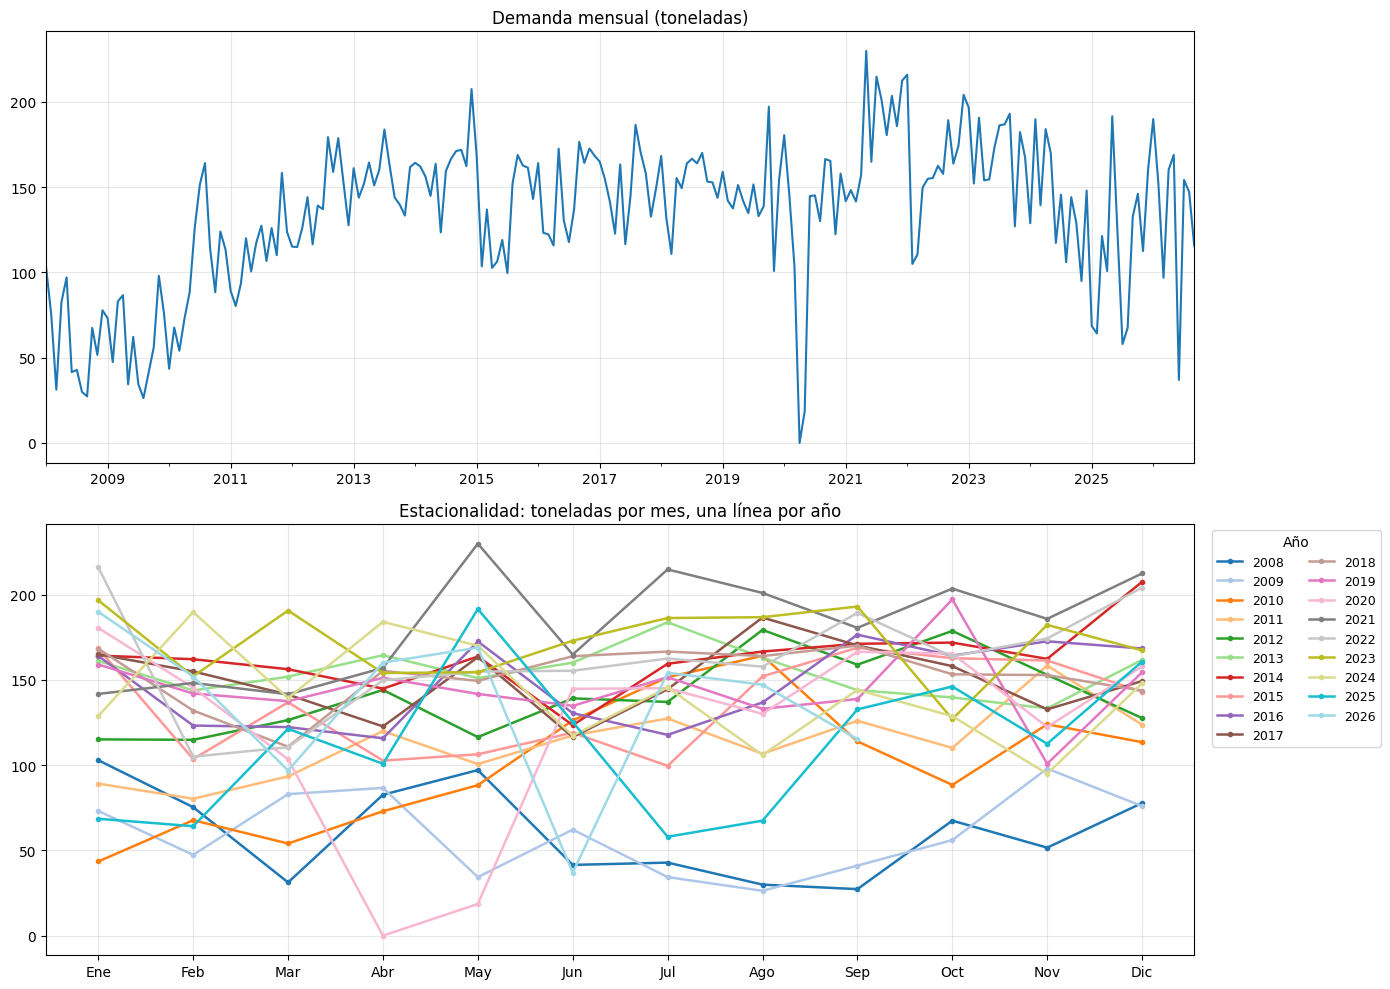

In [ ]:
import matplotlib.cm as cm

fig, ax = plt.subplots(2, 1, figsize=(14, 10))

# 1) Serie completa
mensual["toneladas"].plot(ax=ax[0], title="Demanda mensual (toneladas)", color="tab:blue")
ax[0].set_xlabel("")
ax[0].grid(alpha=0.3)

# 2) Estacionalidad: un color por año
tabla = mensual.assign(anio=mensual.index.year, mes=mensual.index.month).pivot(
    index="mes", columns="anio", values="toneladas")

anios = list(tabla.columns)
colores = cm.get_cmap("tab20", len(anios))          # 20 colores bien distintos

for i, anio in enumerate(anios):
    ax[1].plot(tabla.index, tabla[anio], color=colores(i), marker="o", markersize=3,
               linewidth=1.8, label=str(anio))

ax[1].set_title("Estacionalidad: toneladas por mes, una línea por año")
ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
ax[1].grid(alpha=0.3)
ax[1].legend(title="Año", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

meses_txt = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

tabla = mensual.assign(anio=mensual.index.year, mes=mensual.index.month).pivot(
    index="mes", columns="anio", values="toneladas")
anios = list(tabla.columns)
cmap = plt.get_cmap("tab20", len(anios))
color_de = {a: cmap(i) for i, a in enumerate(anios)}

sel = widgets.SelectMultiple(options=anios, value=(2020, 2025), rows=12,
                             description="Años", layout=widgets.Layout(width="150px"))
modo = widgets.RadioButtons(options=["Resaltar (resto en gris)", "Mostrar solo los elegidos"],
                            description="Modo", layout=widgets.Layout(width="360px"))
prom = widgets.Dropdown(options=["Todos los años", "Solo años elegidos", "Desde 2011", "Ninguno"],
                        value="Todos los años", description="Promedio",
                        layout=widgets.Layout(width="360px"))
salida = widgets.Output()

def dibujar(_=None):
    elegidos = list(sel.value)
    solo = modo.value.startswith("Mostrar")
    with salida:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(12, 6))
        for a in anios:
            if not elegidos:
                ax.plot(tabla.index, tabla[a], color=color_de[a], lw=1.5, marker="o", ms=3, label=str(a))
            elif a in elegidos:
                ax.plot(tabla.index, tabla[a], color=color_de[a], lw=3, marker="o", ms=5, label=str(a), zorder=3)
            elif not solo:
                ax.plot(tabla.index, tabla[a], color="lightgray", lw=1, zorder=1)

        # Promedio mensual según la opción elegida
        if prom.value == "Todos los años":
            cols, txt = anios, "Promedio (todos)"
        elif prom.value == "Solo años elegidos":
            cols, txt = elegidos, "Promedio (elegidos)"
        elif prom.value == "Desde 2011":
            cols, txt = [a for a in anios if a >= 2011], "Promedio (desde 2011)"
        else:
            cols, txt = [], ""
        if cols:
            p = tabla[cols].mean(axis=1)
            ax.plot(p.index, p.values, color="red", lw=4, ls="--", marker="s", ms=6,
                    label=txt, zorder=10)
        elif prom.value == "Solo años elegidos":
            print("Elige al menos un año para calcular este promedio.")

        ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses_txt)
        ax.set_ylabel("Toneladas"); ax.grid(alpha=0.3)
        ax.set_title("Estacionalidad: toneladas por mes")
        ax.legend(title="Año", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2)
        plt.tight_layout(); plt.show()

for w in (sel, modo, prom):
    w.observe(dibujar, names="value")

display(widgets.HBox([sel, widgets.VBox([modo, prom])]), salida)
dibujar()

Output()

In [ ]:
print(tabla.mean(axis=1).round(1))

mes
1     141.9
2     121.2
3     118.3
4     124.7
5     135.4
6     123.8
7     135.9
8     137.1
9     143.6
10    143.4
11    137.4
12    149.8
dtype: float64


## 10. Diagnóstico de la serie
Revisa los meses muy bajos, el nivel por año y la fuerza de la estacionalidad (STL y ACF). El resultado define si conviene SARIMA con s=12 o un modelo más simple. Se ejecuta después de la celda 8.

Meses por debajo de 70 t:


,toneladas,n_pedidos,n_clientes
fecha,,,
2008-03-01,31.2,9,5
2008-06-01,41.5,9,5
2008-07-01,42.8,9,4
2008-08-01,29.9,11,6
2008-09-01,27.3,11,6
2008-10-01,67.4,14,7
2008-11-01,51.6,10,5
2009-02-01,47.4,11,6
2009-05-01,34.4,8,5



Nivel y variabilidad por anho:


,mean,std,min,max
fecha,,,,
2008,60.6,26.7,27.3,102.9
2009,59.9,23.5,26.3,98.0
2010,100.7,37.8,43.5,164.1
2011,112.8,21.0,80.3,158.4
2012,140.9,22.8,114.8,179.3
2013,154.8,13.7,133.3,183.8
2014,162.8,19.3,123.4,207.5
2015,135.4,27.7,99.6,168.8
2016,147.0,24.5,115.8,176.5



Fuerza estacional: 0.10 (0 = nada, 1 = muy fuerte)
Efecto estacional por mes (toneladas):
Ene    -3.2
Feb    -5.3
Mar   -15.1
Abr    -2.1
May     4.1
Jun   -15.9
Jul     6.4
Ago    10.5
Sep    12.0
Oct     7.2
Nov    -2.7
Dic     7.6
dtype: float64


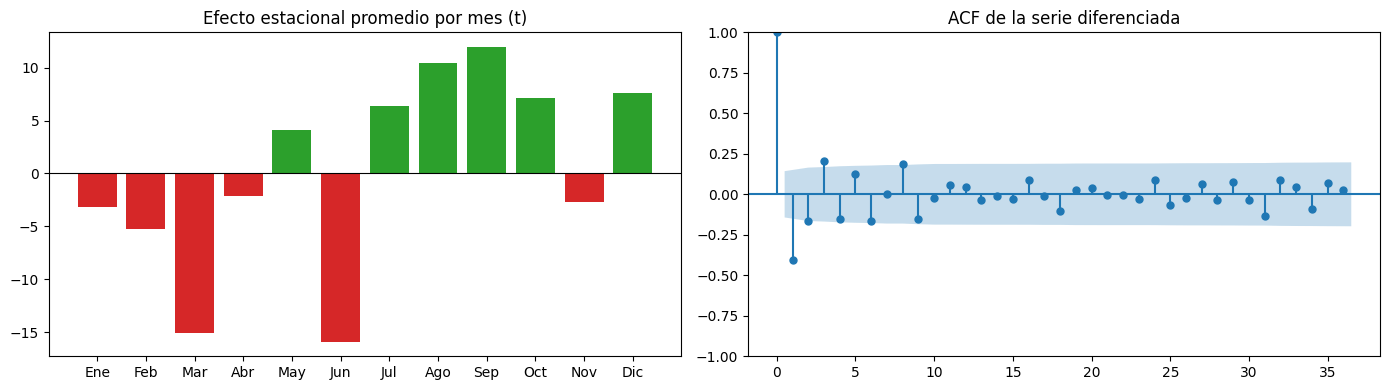

In [ ]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

y = mensual["toneladas"]

#1) Meses muy bajos(para revisar si son reales o errores)
print("Meses por debajo de 70 t:")
display(mensual.loc[y < 70, ["toneladas", "n_pedidos", "n_clientes"]].round(1))

#2) Nivel y variabiliad por anho
print("\nNivel y variabilidad por anho:")
display(mensual.groupby(mensual.index.year)["toneladas"]
        .agg(["mean", "std", "min", "max"]).round(1))

#3) Fuerza de la estacionalidad (desde 2011, con COVID suavizado)
y2 = y.loc["2011-01-01":].copy()
y2.loc["2020-04-01":"2020-05-01"] = np.nan
y2 = y2.interpolate()
stl = STL(y2, period=12, robust=True).fit()
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"\nFuerza estacional: {Fs:.2f} (0 = nada, 1 = muy fuerte)")

#4) Efecto estacional por mes y ACF
meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
efecto = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print("Efecto estacional por mes (toneladas):")
print(pd.Series(efecto.values, index=meses).round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
colores = ["tab:green" if v >= 0 else "tab:red" for v in efecto.values]
ax[0].bar(meses, efecto.values, color=colores)
ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_title("Efecto estacional promedio por mes (t)")
plot_acf(y2.diff().dropna(), lags=36, ax=ax[1], title="ACF de la serie diferenciada")
plt.tight_layout()
plt.show()

In [ ]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

d = y2.to_frame("t")
d["mes"] = d.index.month
d["anio"] = d.index.year

m0 = smf.ols("t ~ C(anio)", d).fit()               # solo nivel por año
m1 = smf.ols("t ~ C(anio) + C(mes)", d).fit()      # nivel por año + mes
print(anova_lm(m0, m1).round(4))
print(f"\nR2 solo año: {m0.rsquared:.3f} | R2 año + mes: {m1.rsquared:.3f}")

   df_resid          ssr  df_diff     ss_diff       F  Pr(>F)
0     173.0  123958.0008      0.0         NaN     NaN     NaN
1     162.0  102871.6545     11.0  21086.3463  3.0188  0.0011

R2 solo año: 0.330 | R2 año + mes: 0.444


#11. Preparado de la serie y modelos base

Entrenamiento: 2011-01-01 -> 2024-12-01 (168 meses)
Prueba:        2025-01-01 -> 2026-09-01 (21 meses)


,MAE (t),RMSE (t),WAPE (%)
Promedio últimos 12 meses,36.42,43.89,-5.23
Ingenuo (último mes),39.05,50.38,-20.87
"Estacional (mismo mes, anho anterior)",39.39,50.62,-17.54
Promedio todo el entrenamiento,39.76,51.49,-22.62


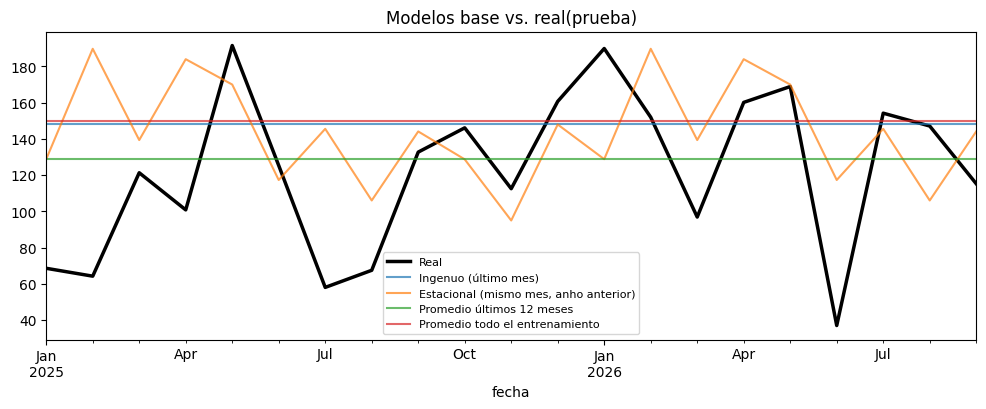

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

#--- Serie para modelar: desde 2011, con abril-mayo 2020(COVID) interpolados ---
y = mensual["toneladas"].loc["2011-01-01":].copy()
y_modelo = y.copy()
y_modelo.loc["2020-04-01":"2020-05-01"] = np.nan
y_modelo = y_modelo.interpolate()

# --- División cronológica ---
FIN_TRAIN = "2024-12-01"
train = y_modelo.loc[:FIN_TRAIN]
test = y.loc["2025-01-01":]
print(f"Entrenamiento: {train.index[0].date()} -> {train.index[-1].date()} ({len(train)} meses)")
print(f"Prueba:        {test.index[0].date()} -> {test.index[-1].date()} ({len(test)} meses)")

def metricas(real, pred):
  mae = mean_absolute_error(real, pred)
  rmse = np.sqrt(mean_squared_error(real, pred))
  wape = 100 * (real - pred).sum() / real.sum()
  return {"MAE (t)": mae, "RMSE (t)": rmse, "WAPE (%)": wape}

# --- Modelos base ---
base = {
      "Ingenuo (último mes)": pd.Series(train.iloc[-1], index=test.index),
      "Estacional (mismo mes, anho anterior)": pd.Series(np.resize(train.iloc[-12:].values, len(test)), index=test.index),
      "Promedio últimos 12 meses": pd.Series(train.iloc[-12].mean(), index=test.index),
      "Promedio todo el entrenamiento": pd.Series(train.mean(), index=test.index),
}
resutlados = pd.DataFrame({k: metricas(test, p) for k, p in base.items()}).T.round(2)
display(resutlados.sort_values("MAE (t)"))

ax = test.plot(label="Real", lw=2.5, color="black", figsize=(12,4))
for k, p in base.items():
  p.plot(ax=ax, label=k, alpha=0.7)
ax.legend(fontsize=8); ax.set_title("Modelos base vs. real(prueba)"); plt.show()

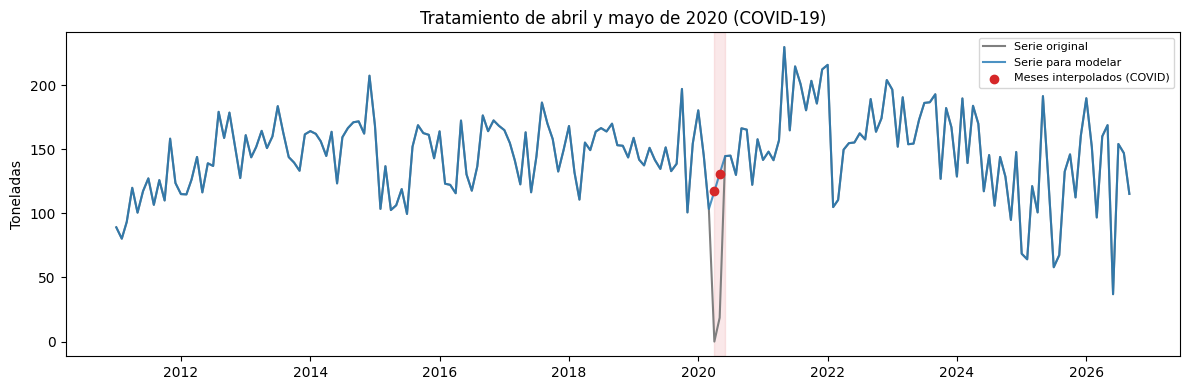

In [ ]:
y_orig = mensual["toneladas"].loc["2011-01-01":]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_orig, color="tab:gray", lw=1.5, label="Serie original")
ax.plot(y_modelo, color="tab:blue", lw=1.5, alpha=0.8, label="Serie para modelar")
ax.scatter(y_modelo.loc["2020-04-01":"2020-05-01"].index,
           y_modelo.loc["2020-04-01":"2020-05-01"].values,
           color="tab:red", zorder=3, label="Meses interpolados (COVID)")
ax.axvspan("2020-04-01", "2020-05-31", color="tab:red", alpha=0.1)
ax.set_title("Tratamiento de abril y mayo de 2020 (COVID-19)")
ax.set_ylabel("Toneladas"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

##12. Regresion lineal

R2 entrenamiento:  0.217
Tedencia: 0.173 t por mes (p = 0.000)


,coef (t),p-valor
const,144.961,0.000
m_2,-23.087,0.019
m_3,-25.753,0.009
m_4,-17.299,0.077
m_5,-8.738,0.371
m_6,-19.292,0.049
m_7,-6.474,0.507
m_8,-4.669,0.632
m_9,4.317,0.658
m_10,-1.114,0.909


{'MAE (t)': 47.10132933237344, 'RMSE (t)': np.float64(60.14063986438153), 'WAPE (%)': np.float64(-35.264165468537136)}


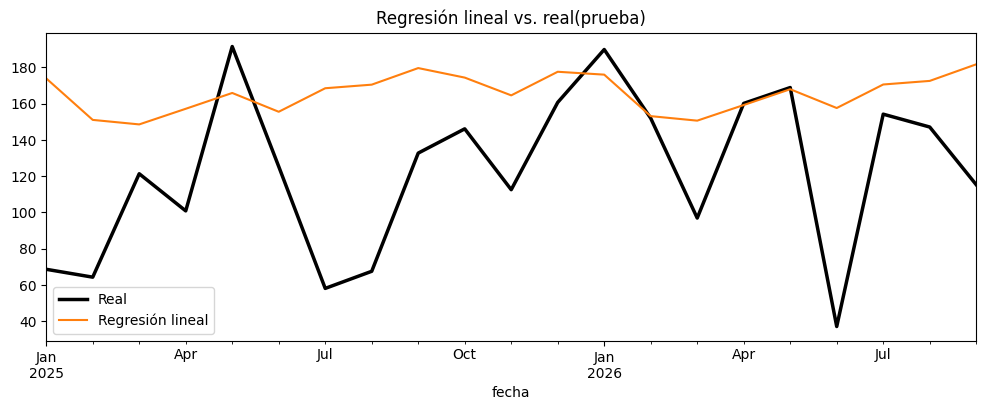

In [ ]:
import statsmodels.api as sm

def disenho(idx, anho0=2011):
  mes =  pd.Categorical(idx.month, categories=range(1, 13))
  X = pd.get_dummies(mes, prefix="m", drop_first=True).astype(float)
  X.index = idx
  X["t"] = (idx.year - anho0) * 12 + idx.month - 1
  return sm.add_constant(X, has_constant="add")

X_tr, X_te = disenho(train.index), disenho(test.index)
rl = sm.OLS(train, X_tr).fit()

pred_rl = pd.Series(rl.predict(X_te), index=test.index)
print(f"R2 entrenamiento: {rl.rsquared: .3f}")
print(f"Tedencia: {rl.params['t']:.3f} t por mes (p = {rl.pvalues['t']:.3f})")
display(pd.DataFrame({"coef (t)": rl.params, "p-valor": rl.pvalues}).round(3))

print(metricas(test, pred=pred_rl))
ax = test.plot(label="Real", lw=2.5, color="black", figsize=(12,4))
pred_rl.plot(ax=ax, label="Regresión lineal", color="tab:orange")
ax.legend(); ax.set_title("Regresión lineal vs. real(prueba)"); plt.show()

##13. SARIMA

train: 168 meses | freq: <MonthBegin> | NaN: 0
Modelos ajustados: 144 de 144


,orden,estacional,AIC
91,"(1, 1, 2)","(0, 1, 1, 12)",1318.328968
43,"(0, 1, 2)","(0, 1, 1, 12)",1318.331424
139,"(2, 1, 2)","(0, 1, 1, 12)",1318.794953
67,"(1, 0, 2)","(0, 1, 1, 12)",1319.538182
115,"(2, 0, 2)","(0, 1, 1, 12)",1319.596464
95,"(1, 1, 2)","(1, 1, 1, 12)",1320.322160
47,"(0, 1, 2)","(1, 1, 1, 12)",1320.331231
143,"(2, 1, 2)","(1, 1, 1, 12)",1320.789225


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6889      0.244     -2.825      0.005      -1.167      -0.211
ma.L1          0.0559      0.210      0.267      0.790      -0.355       0.467
ma.L2         -0.6023      0.161     -3.740      0.000      -0.918      -0.287
ma.S.L12      -1.0000   1257.987     -0.001      0.999   -2466.609    2464.609
sigma2       568.6412   7.15e+05      0.001      0.999    -1.4e+06     1.4e+06

Ljung-Box de residuos:


,lb_stat,lb_pvalue
12,15.842,0.199
24,20.144,0.689


{'MAE (t)': 35.05666291556488, 'RMSE (t)': np.float64(42.54312948755506), 'WAPE (%)': np.float64(-5.279771226257046)}


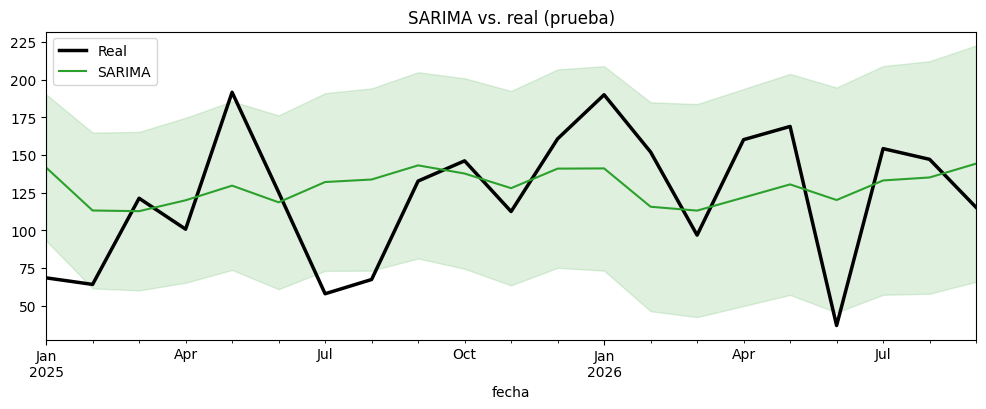

In [ ]:
import itertools, warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")

# Comprobación previa: estas variables las crea la celda de modelos base
for nombre in ["train", "test", "metricas", "base"]:
    if nombre not in globals():
        raise NameError(f"Falta '{nombre}'. Ejecuta primero la celda 'Preparación de la serie y modelos base'.")
print(f"train: {len(train)} meses | freq: {train.index.freq} | NaN: {train.isna().sum()}")

resultados_s, primer_error = [], None
for p, d, q, P, D, Q in itertools.product([0,1,2], [0,1], [0,1,2], [0,1], [0,1], [0,1]):
    try:
        m = SARIMAX(train, order=(p,d,q), seasonal_order=(P,D,Q,12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        resultados_s.append({"orden": (p,d,q), "estacional": (P,D,Q,12), "AIC": m.aic})
    except Exception as e:
        if primer_error is None:
            primer_error = repr(e)

print(f"Modelos ajustados: {len(resultados_s)} de 144")
if primer_error:
    print("Primer error encontrado:", primer_error)
if not resultados_s:
    raise RuntimeError("Ningún modelo se pudo ajustar; revisa el error de arriba.")

top = pd.DataFrame(resultados_s).sort_values("AIC").head(8)
display(top)

mejor = top.iloc[0]
sar = SARIMAX(train, order=mejor["orden"], seasonal_order=mejor["estacional"],
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(sar.summary().tables[1])

fc = sar.get_forecast(len(test))
pred_sar = fc.predicted_mean.set_axis(test.index)
ic = fc.conf_int().set_axis(test.index)

# Residuos: ¿quedó estructura sin explicar? (p > 0.05 = bien)
print("\nLjung-Box de residuos:")
display(acorr_ljungbox(sar.resid.iloc[13:], lags=[12, 24]).round(3))

print(metricas(test, pred_sar))
ax = test.plot(label="Real", lw=2.5, color="black", figsize=(12, 4))
pred_sar.plot(ax=ax, label="SARIMA", color="tab:green")
ax.fill_between(test.index, ic.iloc[:, 0], ic.iloc[:, 1], color="tab:green", alpha=0.15)
ax.legend(); ax.set_title("SARIMA vs. real (prueba)"); plt.show()

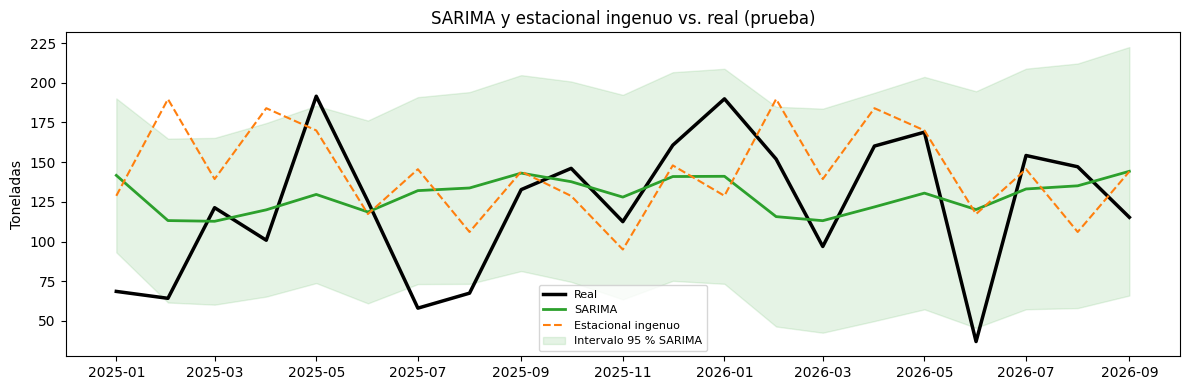

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test, color="black", lw=2.5, label="Real")
ax.plot(pred_sar, color="tab:green", lw=2, label="SARIMA")
ax.plot(base["Estacional (mismo mes, anho anterior)"], color="tab:orange",
        lw=1.5, ls="--", label="Estacional ingenuo")
ax.fill_between(test.index, ic.iloc[:, 0], ic.iloc[:, 1],
                color="tab:green", alpha=0.12, label="Intervalo 95 % SARIMA")
ax.set_ylabel("Toneladas"); ax.legend(fontsize=8)
ax.set_title("SARIMA y estacional ingenuo vs. real (prueba)")
plt.tight_layout(); plt.show()

# 14. Comparación (versión corregida)

In [ ]:
def metricas(real, pred):
    real = pd.Series(real)
    pred = pd.Series(np.asarray(pred), index=real.index)
    err = real - pred
    return {"MAE (t)": float(err.abs().mean()),
            "RMSE (t)": float(np.sqrt((err**2).mean())),
            "WAPE (%)": float(100 * err.abs().sum() / real.sum()),
            "Sesgo (%)": float(100 * err.sum() / real.sum())}   # negativo = pronostica de más

comp = pd.DataFrame({**{k: metricas(test, p) for k, p in base.items()},
                     "Regresión lineal": metricas(test, pred_rl),
                     "SARIMA": metricas(test, pred_sar)}).T.round(2)
display(comp.sort_values("MAE (t)"))

,MAE (t),RMSE (t),WAPE (%),Sesgo (%)
SARIMA,35.06,42.54,28.64,-5.28
Promedio últimos 12 meses,36.42,43.89,29.76,-5.23
Ingenuo (último mes),39.05,50.38,31.90,-20.87
"Estacional (mismo mes, anho anterior)",39.39,50.62,32.18,-17.54
Promedio todo el entrenamiento,39.76,51.49,32.48,-22.62
Regresión lineal,47.10,60.14,38.48,-35.26


#Metricas completas de Evaluacion


In [ ]:
def metricas_completas(real, pred, train=None, ic=None):
    real = pd.Series(real)
    pred = pd.Series(np.asarray(pred), index=real.index)
    err = real - pred
    wape = 100 * err.abs().sum() / real.sum()
    out = {
        "MAE (t)":            err.abs().mean(),
        "RMSE (t)":           np.sqrt((err**2).mean()),
        "MAPE (%)":           100 * (err.abs() / real).mean(),
        "sMAPE (%)":          100 * (2 * err.abs() / (real.abs() + pred.abs())).mean(),
        "WAPE (%)":           wape,
        "Precisión (%)":      100 - wape,
        "Sesgo (%)":          100 * err.sum() / real.sum(),
        "R2 fuera de muestra": 1 - (err**2).sum() / ((real - real.mean())**2).sum(),
    }
    if train is not None:    # MASE: error relativo a repetir el mismo mes del año anterior
        out["MASE"] = err.abs().mean() / train.diff(12).abs().mean()
    if ic is not None:       # ¿cuántos meses reales cayeron dentro del intervalo?
        dentro = (real >= ic.iloc[:, 0]) & (real <= ic.iloc[:, 1])
        out["Cobertura IC 95% (%)"] = 100 * dentro.mean()
    return out

tabla = {k: metricas_completas(test, p, train) for k, p in base.items()}
tabla["Regresión lineal"] = metricas_completas(test, pred_rl, train)
tabla["SARIMA"] = metricas_completas(test, pred_sar, train, ic)
tabla = pd.DataFrame(tabla).T

# Mejora frente al promedio de 12 meses (el modelo simple de referencia)
ref = tabla.loc["Promedio últimos 12 meses", "MAE (t)"]
tabla["Mejora vs promedio 12m (%)"] = 100 * (1 - tabla["MAE (t)"] / ref)
display(tabla.round(2).sort_values("MAE (t)"))

# Error mes a mes del SARIMA
det = pd.DataFrame({"Real": test, "Pronóstico": pred_sar})
det["Error (t)"] = det["Real"] - det["Pronóstico"]
det["Error (%)"] = 100 * det["Error (t)"] / det["Real"]
display(det.round(1))

,MAE (t),RMSE (t),MAPE (%),sMAPE (%),WAPE (%),Precisión (%),Sesgo (%),R2 fuera de muestra,MASE,Cobertura IC 95% (%),Mejora vs promedio 12m (%)
SARIMA,35.06,42.54,42.74,31.10,28.64,71.36,-5.28,0.04,1.29,76.19,3.75
Promedio últimos 12 meses,36.42,43.89,44.44,32.13,29.76,70.24,-5.23,-0.02,1.34,NaN,0.00
Ingenuo (último mes),39.05,50.38,53.02,33.43,31.90,68.10,-20.87,-0.35,1.44,NaN,-7.20
"Estacional (mismo mes, anho anterior)",39.39,50.62,49.67,33.47,32.18,67.82,-17.54,-0.36,1.45,NaN,-8.13
Promedio todo el entrenamiento,39.76,51.49,54.27,33.83,32.48,67.52,-22.62,-0.41,1.47,NaN,-9.15
Regresión lineal,47.10,60.14,63.65,37.84,38.48,61.52,-35.26,-0.92,1.74,NaN,-29.31


,Real,Pronóstico,Error (t),Error (%)
fecha,,,,
2025-01-01,68.6,141.7,-73.1,-106.7
2025-02-01,64.2,113.2,-49.0,-76.3
2025-03-01,121.3,112.7,8.6,7.1
2025-04-01,100.8,120.0,-19.2,-19.0
2025-05-01,191.6,129.7,61.9,32.3
2025-06-01,125.3,118.6,6.7,5.3
2025-07-01,58.0,132.1,-74.1,-127.7
2025-08-01,67.4,133.7,-66.3,-98.3
2025-09-01,132.7,143.1,-10.4,-7.8


#15. Validación Móvil


In [ ]:
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX

serie = y_modelo.copy()              # desde 2011, COVID interpolado
H = 12
fines = pd.date_range("2018-12-01", "2025-09-01", freq="6MS")

def f_estacional(tr, h): return np.resize(tr.iloc[-12:].values, h)
def f_prom12(tr, h):     return np.repeat(tr.iloc[-12:].mean(), h)
def f_regresion(tr, h):
    idx_f = pd.date_range(tr.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    m = sm.OLS(tr, disenio(tr.index)).fit()
    return m.predict(disenio(idx_f)).values
def hacer_sarima(orden, est):
    def f(tr, h):
        m = SARIMAX(tr, order=orden, seasonal_order=est, enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
        return m.forecast(h).values
    return f

def f_regresion_ventana(tr, h, meses=36):
    tr2 = tr.iloc[-meses:]
    idx_f = pd.date_range(tr.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    m = sm.OLS(tr2, disenio(tr2.index).drop(columns="t")).fit()
    return m.predict(disenio(idx_f).drop(columns="t")).values

def f_prom_estacional(tr, h, anios=6):
    ref = tr.iloc[-12 * anios:]
    bloque = np.arange(len(ref)) // 12                       # bloques de 12 meses
    desv = ref - ref.groupby(bloque).transform("mean")       # desvío respecto al nivel de su bloque
    efecto = desv.groupby(desv.index.month).mean()
    idx_f = pd.date_range(tr.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    return tr.iloc[-12:].mean() + efecto.reindex(idx_f.month).values

modelos = {
    "Promedio 12 meses": f_prom12,
    "Promedio 12m + estacional": f_prom_estacional,
    "Regresión ventana 36m (sin tendencia)": f_regresion_ventana,
    "Regresión (tendencia + mes)": f_regresion,
    "SARIMA (0,1,2)(0,1,1,12)": hacer_sarima((0,1,2), (0,1,1,12)),
    "SARIMA (1,0,2)(0,1,1,12)": hacer_sarima((1,0,2), (0,1,1,12)),
}

filas, errores = [], []
for fin in fines:
    tr = serie.loc[:fin]
    te = serie.loc[fin + pd.offsets.MonthBegin(1):].iloc[:H]
    if len(te) < H:
        continue
    for nombre, f in modelos.items():
        try:
            filas.append({"corte": fin.date(), "modelo": nombre, **metricas(te, f(tr, H))})
        except Exception as e:
            errores.append((nombre, fin.date(), repr(e)))

res = pd.DataFrame(filas)
print("Promedio sobre", res["corte"].nunique(), "cortes:")
display(res.groupby("modelo")[["MAE (t)", "RMSE (t)", "WAPE (%)", "Sesgo (%)"]]
        .mean().round(2).sort_values("MAE (t)"))
print("MAE por corte (t):")
display(res.pivot(index="corte", columns="modelo", values="MAE (t)").round(1))
if errores:
    print("Errores:", errores[:3])

Promedio sobre 14 cortes:


,MAE (t),RMSE (t),WAPE (%),Sesgo (%)
modelo,,,,
"SARIMA (1,0,2)(0,1,1,12)",27.82,34.34,19.29,-3.74
"SARIMA (0,1,2)(0,1,1,12)",28.79,35.13,19.95,-6.72
Promedio 12m + estacional,29.08,35.38,20.13,-4.75
Promedio 12 meses,29.10,35.25,20.29,-4.75


MAE por corte (t):


modelo,Promedio 12 meses,Promedio 12m + estacional,"SARIMA (0,1,2)(0,1,1,12)","SARIMA (1,0,2)(0,1,1,12)"
corte,,,,
2018-12-01,16.2,17.2,16.2,15.1
2019-06-01,22.9,22.2,22.5,21.9
2019-12-01,17.7,13.4,14.8,14.7
2020-06-01,19.5,24.2,21.4,19.9
2020-12-01,39.6,43.1,42.3,39.0
2021-06-01,35.6,31.9,28.4,33.8
2021-12-01,30.5,26.0,38.6,22.5
2022-06-01,15.5,16.3,15.8,20.9
2022-12-01,20.0,22.6,16.7,21.5


Errores: [('Regresión ventana 36m (sin tendencia)', datetime.date(2018, 12, 1), 'NameError("name \'disenio\' is not defined")'), ('Regresión (tendencia + mes)', datetime.date(2018, 12, 1), 'NameError("name \'disenio\' is not defined")'), ('Regresión ventana 36m (sin tendencia)', datetime.date(2019, 6, 1), 'NameError("name \'disenio\' is not defined")')]


# 16. Pronóstico fiinal(octubre 2026 a septiembre2027)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8850      0.060     14.841      0.000       0.768       1.002
ma.L1         -0.6392      0.105     -6.110      0.000      -0.844      -0.434
ma.L2         -0.0315      0.080     -0.392      0.695      -0.189       0.126
ma.S.L12      -0.9398      0.159     -5.897      0.000      -1.252      -0.627
sigma2       761.8819     92.405      8.245      0.000     580.771     942.993

Ljung-Box de residuos (p > 0.05 = bien):


,lb_stat,lb_pvalue
12,16.584,0.166
24,18.488,0.779


Pronóstico en toneladas:


,SARIMA (t),80% bajo (t),80% alto (t),95% bajo (t),95% alto (t),Control simple (t)
2026-10-01,141.2,105.4,176.9,86.5,195.9,141.1
2026-11-01,132.4,95.6,169.3,76.1,188.7,130.7
2026-12-01,151.1,113.6,188.5,93.8,208.3,160.4
2027-01-01,148.4,110.5,186.3,90.5,206.3,142.3
2027-02-01,126.3,88.1,164.6,67.9,184.8,120.5
2027-03-01,123.9,85.4,162.4,65.0,182.7,118.7
2027-04-01,135.8,97.1,174.5,76.6,195.0,136.3
2027-05-01,151.6,112.8,190.5,92.2,211.1,163.6
2027-06-01,127.1,88.1,166.1,67.5,186.7,114.1
2027-07-01,143.2,104.2,182.3,83.5,203.0,138.9


Pronóstico en bolsas:


,SARIMA (bolsas),80% bajo (bolsas),80% alto (bolsas),95% bajo (bolsas),95% alto (bolsas),Control simple (bolsas)
2026-10-01,2824,2109,3539,1730,3917,2821
2026-11-01,2649,1912,3385,1523,3775,2613
2026-12-01,3021,2273,3769,1877,4165,3208
2027-01-01,2968,2211,3726,1810,4127,2845
2027-02-01,2527,1762,3291,1357,3696,2410
2027-03-01,2478,1708,3247,1300,3655,2374
2027-04-01,2716,1942,3490,1533,3900,2725
2027-05-01,3033,2255,3810,1844,4221,3272
2027-06-01,2542,1763,3322,1350,3735,2282
2027-07-01,2865,2083,3646,1669,4060,2777


Total 12 meses: 1,681 t = 33,621 bolsas


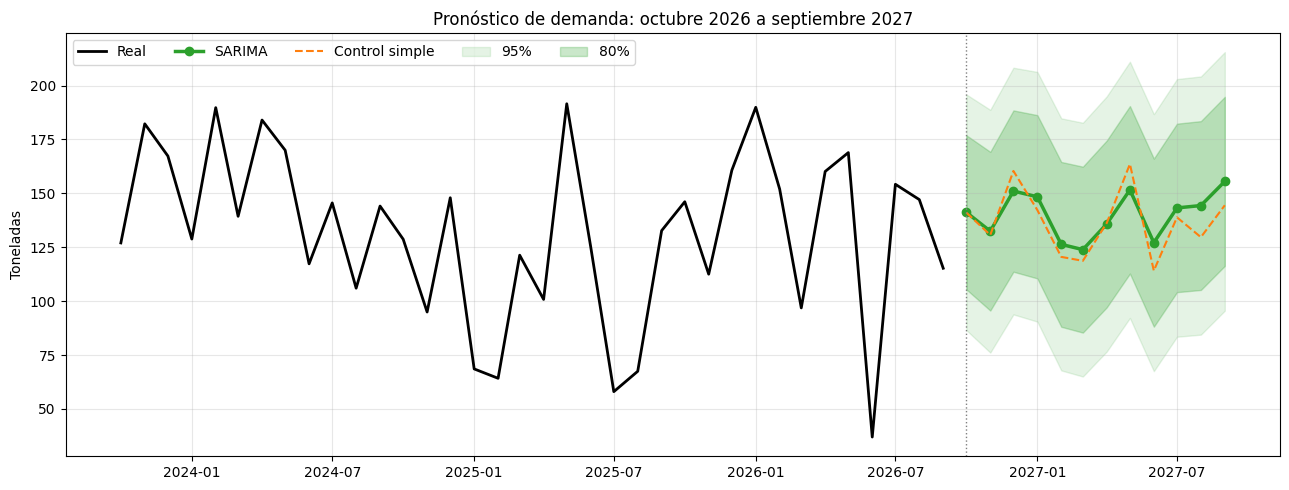

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

H = 12
mod = SARIMAX(y_modelo, order=(1,0,2), seasonal_order=(0,1,1,12),
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(mod.summary().tables[1])
print("\nLjung-Box de residuos (p > 0.05 = bien):")
display(acorr_ljungbox(mod.resid.iloc[13:], lags=[12, 24]).round(3))

idx = pd.date_range(y_modelo.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
fc = mod.get_forecast(H)
media = fc.predicted_mean.values
ic80 = fc.conf_int(alpha=0.20).values        # intervalo de 80%
ic95 = fc.conf_int(alpha=0.05).values        # intervalo de 95%
control = f_prom_estacional(y_modelo, H)     # modelo simple de referencia

pron = pd.DataFrame({
    "SARIMA (t)": media,
    "80% bajo (t)": np.maximum(ic80[:, 0], 0), "80% alto (t)": ic80[:, 1],
    "95% bajo (t)": np.maximum(ic95[:, 0], 0), "95% alto (t)": ic95[:, 1],
    "Control simple (t)": control,
}, index=idx)

# Conversión a bolsas de 50 kg: 1 t = 20 bolsas
bolsas = (pron * 1000 / KG_POR_BOLSA).round(0).astype(int)
bolsas.columns = [c.replace("(t)", "(bolsas)") for c in bolsas.columns]

print("Pronóstico en toneladas:")
display(pron.round(1))
print("Pronóstico en bolsas:")
display(bolsas)
print(f"Total 12 meses: {pron['SARIMA (t)'].sum():,.0f} t = {bolsas['SARIMA (bolsas)'].sum():,} bolsas")

# Gráfico: últimos 36 meses + pronóstico
fig, ax = plt.subplots(figsize=(13, 5))
hist = y.loc["2023-10-01":]
ax.plot(hist.index, hist.values, color="black", lw=2, label="Real")
ax.plot(idx, media, color="tab:green", lw=2.5, marker="o", label="SARIMA")
ax.plot(idx, control, color="tab:orange", lw=1.5, ls="--", label="Control simple")
ax.fill_between(idx, pron["95% bajo (t)"], pron["95% alto (t)"], color="tab:green", alpha=0.12, label="95%")
ax.fill_between(idx, pron["80% bajo (t)"], pron["80% alto (t)"], color="tab:green", alpha=0.25, label="80%")
ax.axvline(idx[0], color="gray", ls=":", lw=1)
ax.set_ylabel("Toneladas"); ax.grid(alpha=0.3); ax.legend(ncol=5, loc="upper left")
ax.set_title("Pronóstico de demanda: octubre 2026 a septiembre 2027")
plt.tight_layout(); plt.show()

pron.join(bolsas).to_csv("pronostico_12_meses.csv")

#17. Guardar modelo

In [ ]:
import os, json, shutil

CARPETA_APP = "app_pronostico"
os.makedirs(CARPETA_APP, exist_ok=True)

mod.save(os.path.join(CARPETA_APP, "modelo_sarima.pkl"))
y_modelo.rename("toneladas").to_csv(os.path.join(CARPETA_APP, "serie_modelo.csv"), index_label="fecha")
json.dump({"order": [1, 0, 2], "seasonal_order": [0, 1, 1, 12], "kg_por_bolsa": KG_POR_BOLSA},
          open(os.path.join(CARPETA_APP, "config.json"), "w"), indent=2)
shutil.copy("ventas_limpio.csv", CARPETA_APP)
print("Guardado en", CARPETA_APP)

Guardado en app_pronostico
